In [7]:
import os
from google.colab import userdata

# This pulls the info from your private 'Vault'
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

print(" Credentials pulled from Secure Vault.")


 Credentials pulled from Secure Vault.


In [8]:
# 1. Install Libraries
!pip install -q kaggle datasets transformers torchmetrics torchxrayvision

import os
import torch
import pandas as pd
from google.colab import userdata

# 2. Inject Secrets (Ensure you added KAGGLE_USERNAME and KAGGLE_KEY in Colab 🔑)
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

# 3. Download NIH Dataset (Resized version for speed)
!kaggle datasets download -d khanfashee/nih-chest-x-ray-14-224x224-resized
!unzip -q nih-chest-x-ray-14-224x224-resized.zip -d nih_data

print(" Environment Ready: NIH Data unzipped to /content/nih_data")

Dataset URL: https://www.kaggle.com/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized
License(s): CC0-1.0
 99% 2.28G/2.30G [00:20<00:00, 253MB/s]
100% 2.30G/2.30G [00:20<00:00, 118MB/s]
 Environment Ready: NIH Data unzipped to /content/nih_data


In [9]:
import pandas as pd
import numpy as np
import os
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split

# 1. Define paths (Kaggle sometimes puts images inside a subfolder)
csv_path = '/content/nih_data/Data_Entry_2017.csv'
img_dir = '/content/nih_data/images'

if not os.path.exists(img_dir):
    # Fallback if the zip extracted directly into the root folder
    img_dir = '/content/nih_data/'

# 2. Load and clean the CSV
df = pd.read_csv(csv_path)

# 3. Convert 'Pathology1|Pathology2' into a list: ['Pathology1', 'Pathology2']
df['Finding Labels'] = df['Finding Labels'].apply(lambda x: x.split('|'))

# 4. One-Hot Encode the labels (creates a matrix of 0s and 1s)
mlb = MultiLabelBinarizer()
labels_matrix = mlb.fit_transform(df['Finding Labels'])
all_classes = mlb.classes_

# Create a clean DataFrame with just Image Names and their Binary Labels
df_labels = pd.DataFrame(labels_matrix, columns=all_classes)
df_final = pd.concat([df['Image Index'], df_labels], axis=1)

# 5. Split into Training (80%) and Validation (20%)
# We use a subset of 20,000 images right now so you can test the code quickly today.
df_sample = df_final.sample(20000, random_state=42)
train_df, val_df = train_test_split(df_sample, test_size=0.2, random_state=42)

print(f"Labels Processed! Total Pathologies found: {len(all_classes)}")
print(f"Classes: {all_classes}")
print(f"Training on {len(train_df)} images, Validating on {len(val_df)} images.")

Labels Processed! Total Pathologies found: 15
Classes: ['Atelectasis' 'Cardiomegaly' 'Consolidation' 'Edema' 'Effusion'
 'Emphysema' 'Fibrosis' 'Hernia' 'Infiltration' 'Mass' 'No Finding'
 'Nodule' 'Pleural_Thickening' 'Pneumonia' 'Pneumothorax']
Training on 16000 images, Validating on 4000 images.


In [10]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class NIHDataset(Dataset):
    def __init__(self, dataframe, img_dir, classes, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.classes = classes
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        # Load Image
        img_name = self.dataframe.loc[idx, 'Image Index']
        img_path = os.path.join(self.img_dir, img_name)

        # Convert to RGB (some X-rays are grayscale, models expect 3 channels)
        image = Image.open(img_path).convert('RGB')

        # Load Labels (as float32 for PyTorch)
        labels = torch.tensor(self.dataframe.loc[idx, self.classes].values.astype(float), dtype=torch.float32)

        if self.transform:
            image = self.transform(image)

        return image, labels

# Data Augmentation: We flip and rotate images slightly so the AI learns better features
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create the DataLoaders
train_dataset = NIHDataset(train_df, img_dir, all_classes, transform=train_transforms)
val_dataset = NIHDataset(val_df, img_dir, all_classes, transform=val_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"DataLoaders Ready: {len(train_loader)} training batches.")

DataLoaders Ready: 500 training batches.


In [11]:
import torchvision.models as models
import torch.nn as nn

class MedicalVisionEncoder(nn.Module):
    def __init__(self, num_classes):
        super(MedicalVisionEncoder, self).__init__()
        # Load pre-trained DenseNet121
        self.backbone = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

        # Replace the final classification layer for our specific diseases
        num_ftrs = self.backbone.classifier.in_features
        self.backbone.classifier = nn.Linear(num_ftrs, num_classes)
        # Note: We do NOT use Sigmoid here because PyTorch's BCEWithLogitsLoss handles it automatically (and more stably)

    def forward(self, x):
        return self.backbone(x)

# Push model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MedicalVisionEncoder(num_classes=len(all_classes)).to(device)

print(f" Model Initialized and moved to {device}.")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 63.6MB/s]


 Model Initialized and moved to cpu.


In [12]:
import glob
import os

# Search for any .png file inside the unzipped folder
png_files = glob.glob('/content/nih_data/**/*.png', recursive=True)

if png_files:
    # Get the directory of the first image found
    correct_img_dir = os.path.dirname(png_files[0])
    print(f"Found the correct image folder: {correct_img_dir}")

    # Update the DataLoader variable globally
    img_dir = correct_img_dir
else:
    print(" No images found. Did the unzip fail?")

✅ Found the correct image folder: /content/nih_data/images-224/images-224


In [13]:
# 1. Update the image directory variable
img_dir = '/content/nih_data/images-224/images-224'

# 2. Recreate the datasets with the correct path
train_dataset = NIHDataset(train_df, img_dir, all_classes, transform=train_transforms)
val_dataset = NIHDataset(val_df, img_dir, all_classes, transform=val_transforms)

# 3. Recreate the DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"DataLoaders Updated & Ready! Using path: {img_dir}"

✅ DataLoaders Updated & Ready! Using path: /content/nih_data/images-224/images-224


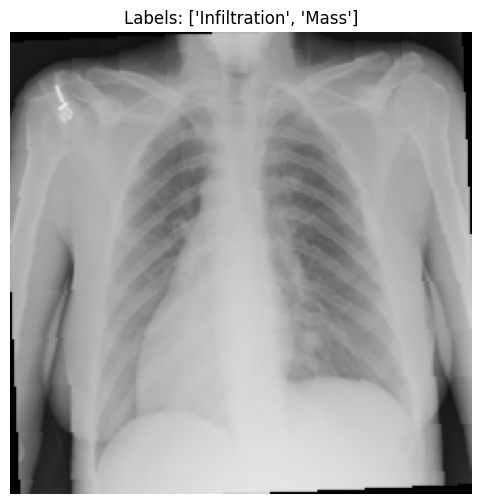

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Fetch one batch of data
images, labels = next(iter(train_loader))

# Plot the first image in the batch
plt.figure(figsize=(6, 6))

# Un-normalize to make the image viewable (reversing the ImageNet normalization)
img_show = images[0].permute(1, 2, 0).numpy() * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
img_show = np.clip(img_show, 0, 1)

plt.imshow(img_show)

# Find which diseases are present (where label == 1)
active_labels = [all_classes[i] for i, val in enumerate(labels[0]) if val == 1]
if not active_labels:
    active_labels = ['No Finding'] # Some images are healthy

plt.title(f"Labels: {active_labels}")
plt.axis('off')
plt.show()

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from tqdm import tqdm
import os
from google.colab import drive

# 1. MOUNT GOOGLE DRIVE (For safe saving)
drive.mount('/content/drive')
save_path = '/content/drive/MyDrive/densenet_nih_weights.pth'

# 2. PRESENTATION SETTINGS
# Set to True for a quick 60-second run to show your professor. Set to False for real training.
DEMO_MODE = True

if DEMO_MODE:
    print("RUNNING IN DEMO MODE: Using a tiny dataset for fast execution.")
    train_df_active = train_df.head(200) # Only use 200 images
    epochs = 1
else:
    print(" RUNNING IN FULL MODE: Training on all available data.")
    train_df_active = train_df
    epochs = 3

# Rebuild DataLoader with the active dataframe
# (Assuming img_dir and train_transforms are already defined from yesterday)
demo_train_dataset = NIHDataset(train_df_active, img_dir, all_classes, transform=train_transforms)
demo_train_loader = DataLoader(demo_train_dataset, batch_size=32, shuffle=True, num_workers=2)

# 3. BUILD THE MODEL
class MedicalVisionEncoder(nn.Module):
    def __init__(self, num_classes=14):
        super(MedicalVisionEncoder, self).__init__()
        self.backbone = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        num_ftrs = self.backbone.classifier.in_features
        self.backbone.classifier = nn.Linear(num_ftrs, num_classes)

    def forward(self, x):
        return self.backbone(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MedicalVisionEncoder(num_classes=14).to(device)

# 4. RESUME CAPABILITY (Check if we already saved a model)
if os.path.exists(save_path):
    print(f"Found existing weights! Loading from {save_path}...")
    model.load_state_dict(torch.load(save_path, map_location=device))
else:
    print("No previous weights found. Starting fresh.")

# 5. GRADER & OPTIMIZER
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 6. THE TRAINING LOOP WITH ACCURACY
print(f"⚙️ Starting training engine on {device}...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_predictions = 0

    loop = tqdm(demo_train_loader, total=len(demo_train_loader), desc=f"Epoch {epoch+1}/{epochs}")

    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        # Calculate Accuracy (Using 0.5 threshold for multi-label sigmoid outputs)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        correct_predictions += (predicted == labels).sum().item()
        total_predictions += labels.numel() # Total number of individual label checks

        running_loss += loss.item()

        # Update progress bar with Loss and live Accuracy
        live_acc = (correct_predictions / total_predictions) * 100
        loop.set_postfix(loss=loss.item(), acc=f"{live_acc:.2f}%")

    # Save after every epoch
    torch.save(model.state_dict(), save_path)
    print(f"\nEpoch {epoch+1} complete! Weights safely saved to Google Drive.")

print("Execution Finished!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⚠️ RUNNING IN DEMO MODE: Using a tiny dataset for fast execution.


NameError: name 'train_df' is not defined